Basic bank data
----------------
Line-to-line voltage: 13.800 kV
Nominal phase voltage: 7.967 kV
Total reactive power: 2.400 MVAr
Capacitor unit reactive power: 200.000 kVAr
Total capacitor units: 12
Capacitors per phase per star: 2
Nominal current per capacitor unit: 25.102 A
Capacitance per capacitor unit: 8.357 microfarads
Nominal full-bank line current: 100.409 A
Neutral link impedance: 0.010000 ohm

Summary results
----------------


,Case,Failed fuses,I_A rms [A],I_B rms [A],I_C rms [A],VN1 magnitude [V],VN1 angle [deg],VN2 magnitude [V],VN2 angle [deg],VN1-VN2 magnitude [V],VN1-VN2 angle [deg],Neutral-to-neutral current rms [A],Neutral-to-neutral current angle [deg]
0,0 failed fuse(s),0,100.408742,100.408742,100.408742,1.127631e-12,-1.536553e-11,1.127631e-12,-1.536553e-11,2.019484e-28,0.010491,2.019484e-26,0.010491
1,1 failed fuse(s),1,82.152607,96.170088,96.170229,7.243122e+02,-1.799941e+02,7.243122e+02,1.799951e+02,1.369210e-01,-90.004923,1.369210e+01,-90.004923
2,2 failed fuse(s),2,60.245245,92.025774,92.026491,1.593487e+03,-1.799935e+02,1.593487e+03,1.799957e+02,3.012262e-01,-90.004332,3.012262e+01,-90.004332



Neutral voltage results
-----------------------


,Case,Neutral,Voltage magnitude [V],Voltage angle [deg],Voltage phasor
0,0 failed fuse(s),Star 1 neutral,1.127631e-12,-1.536553e-11,0.000 ∠ -0.00°
1,0 failed fuse(s),Star 2 neutral,1.127631e-12,-1.536553e-11,0.000 ∠ -0.00°
2,0 failed fuse(s),Star 1 neutral minus Star 2 neutral,2.019484e-28,1.049117e-02,0.000 ∠ 0.01°
3,1 failed fuse(s),Star 1 neutral,7.243122e+02,-1.799941e+02,724.312 ∠ -179.99°
4,1 failed fuse(s),Star 2 neutral,7.243122e+02,1.799951e+02,724.312 ∠ 180.00°
5,1 failed fuse(s),Star 1 neutral minus Star 2 neutral,1.369210e-01,-9.000492e+01,0.137 ∠ -90.00°
6,2 failed fuse(s),Star 1 neutral,1.593487e+03,-1.799935e+02,1593.487 ∠ -179.99°
7,2 failed fuse(s),Star 2 neutral,1.593487e+03,1.799957e+02,1593.487 ∠ 180.00°
8,2 failed fuse(s),Star 1 neutral minus Star 2 neutral,3.012262e-01,-9.000433e+01,0.301 ∠ -90.00°



Branch voltage and current results
----------------------------------


,Case,Star,Phase,Capacitor units in service,Branch voltage rms [V],Branch voltage angle [deg],Branch current rms [A],Branch current angle [deg]
0,0 failed fuse(s),Star 1,A,2,7967.433715,2.174684e-27,50.204371,90.000000
1,0 failed fuse(s),Star 1,B,2,7967.433715,-1.200000e+02,50.204371,-30.000000
2,0 failed fuse(s),Star 1,C,2,7967.433715,1.200000e+02,50.204371,-150.000000
3,0 failed fuse(s),Star 2,A,2,7967.433715,2.174685e-27,50.204371,90.000000
4,0 failed fuse(s),Star 2,B,2,7967.433715,-1.200000e+02,50.204371,-30.000000
5,0 failed fuse(s),Star 2,C,2,7967.433715,1.200000e+02,50.204371,-150.000000
6,1 failed fuse(s),Star 1,A,1,8691.745877,4.923164e-04,27.384203,90.000492
7,1 failed fuse(s),Star 1,B,2,7631.034552,-1.152852e+02,48.084654,-25.285236
8,1 failed fuse(s),Star 1,C,2,7631.169610,1.152848e+02,48.085505,-154.715244
9,1 failed fuse(s),Star 2,A,2,8691.745866,-4.102636e-04,54.768405,89.999590


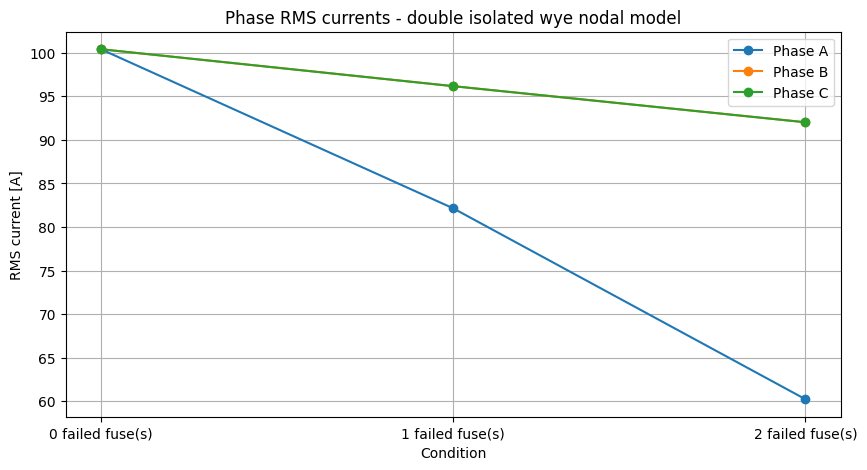

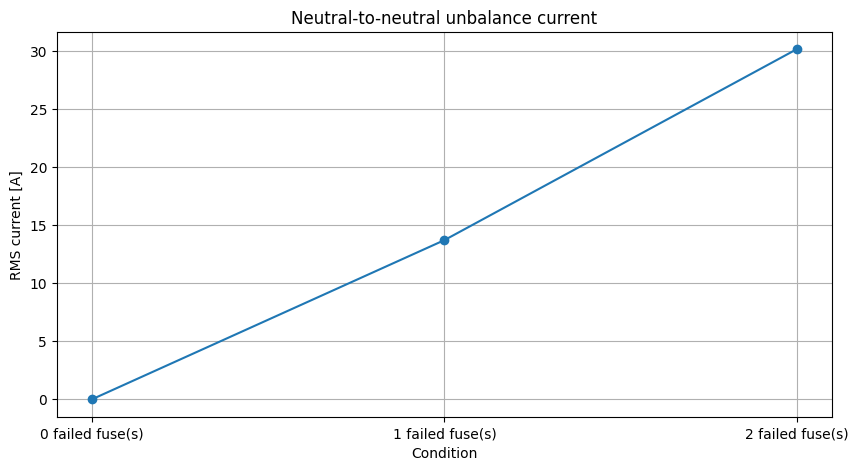

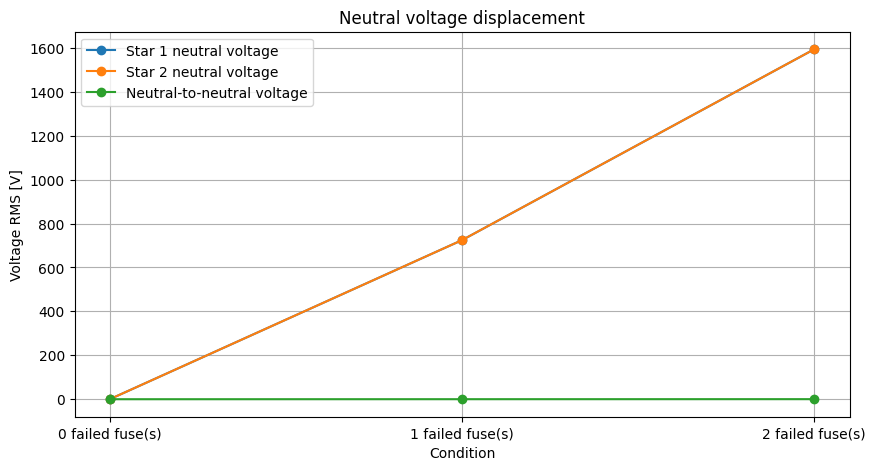

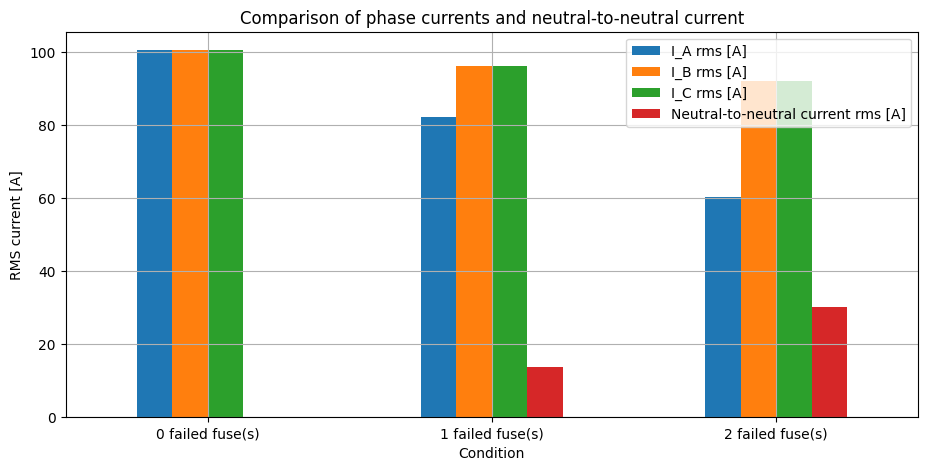

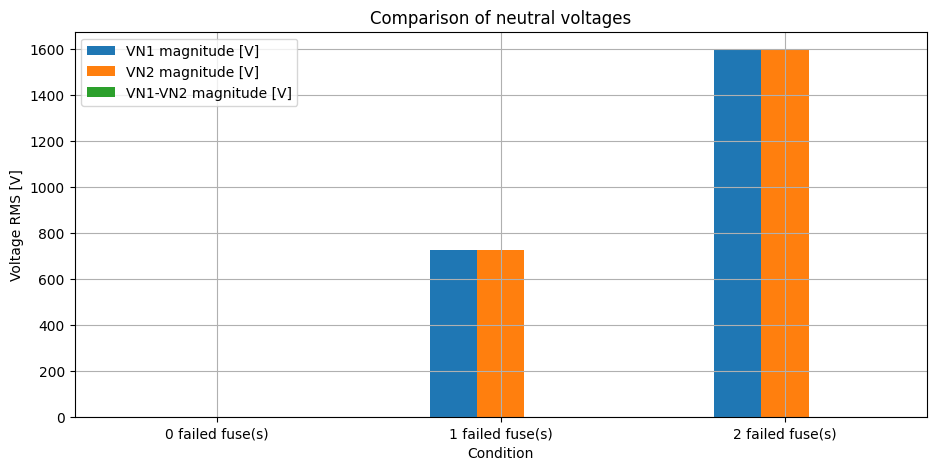


Technical interpretation
-------------------------
This model treats both star neutrals as floating nodes.
The neutral points are not connected to ground.
The source phase voltages are only used as a mathematical reference.
VN1 is the neutral voltage displacement of Star 1.
VN2 is the neutral voltage displacement of Star 2.
VN1-VN2 is the voltage between the two neutral points.
The neutral-to-neutral current exists only if a neutral link impedance is defined.
If neutral_link_ohm is None, there is no physical path between the two neutrals.
With a small neutral_link_ohm, the model represents the unbalance CT path between neutrals.
After fuse failures, the affected star becomes unbalanced and its neutral voltage shifts.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Double isolated wye capacitor bank - nodal model
# ============================================================
# Assumptions:
# - The capacitor bank is a double isolated wye bank.
# - The two neutral points are not grounded.
# - Each neutral point is modeled as a floating node.
# - The neutral-to-neutral branch represents the unbalance CT path.
# - If neutral_link_ohm is None, the two neutrals are completely separated.
# - If neutral_link_ohm is small, the two neutrals are connected by a low impedance.
# - Capacitor units are modeled as ideal capacitive admittances.
# - Failed fuses remove capacitor units from service.
# - The failed fuses are assumed to be in the same phase and in the same branch of one star.
# ============================================================


# ============================================================
# Input data
# ============================================================

V_LL_kV = 13.8
Q_total_MVAr = 2.4
frequency_Hz = 60.0

number_of_capacitors_total = 12
Q_capacitor_kVAr = 200.0

number_of_stars = 2
number_of_phases = 3

failed_phase = "A"
failed_star = "Star 1"

failed_fuses_cases = [0, 1, 2]

# Neutral-to-neutral impedance.
#
# Use None if the two neutral points are completely open.
# In this case, the neutral-to-neutral current will be zero.
#
# Use a small value to represent the unbalance CT connection between neutrals.
# Example: 0.01 ohm, 0.1 ohm, 1.0 ohm.
#
# In real double isolated wye capacitor banks, the neutral CT path is usually
# a very low impedance path between the two neutral points.
neutral_link_ohm = 0.01


# ============================================================
# Base calculations
# ============================================================

V_LL = V_LL_kV * 1e3
Q_total = Q_total_MVAr * 1e6
Q_capacitor = Q_capacitor_kVAr * 1e3

omega = 2 * np.pi * frequency_Hz

V_phase_nominal = V_LL / np.sqrt(3)

capacitors_per_phase_per_star_float = (
    number_of_capacitors_total / (number_of_stars * number_of_phases)
)

if not capacitors_per_phase_per_star_float.is_integer():
    raise ValueError(
        "The total number of capacitors must be divisible by "
        "number_of_stars * number_of_phases."
    )

capacitors_per_phase_per_star = int(capacitors_per_phase_per_star_float)

# For one capacitor unit:
#
# Q = V^2 * B
# B = Q / V^2
# Y = jB
#
# The capacitor unit is assumed to be rated at the nominal phase voltage.
B_capacitor = Q_capacitor / V_phase_nominal**2
Y_capacitor = 1j * B_capacitor

C_capacitor = B_capacitor / omega

I_capacitor_nominal = Q_capacitor / V_phase_nominal
I_bank_nominal = Q_total / (np.sqrt(3) * V_LL)


# ============================================================
# Phasor helper functions
# ============================================================

def polar(magnitude, angle_deg):
    """
    Convert magnitude and angle in degrees to a complex phasor.
    """
    return magnitude * np.exp(1j * np.deg2rad(angle_deg))


def phasor_magnitude_angle(phasor):
    """
    Return magnitude and angle in degrees of a complex phasor.
    """
    magnitude = np.abs(phasor)
    angle_deg = np.rad2deg(np.angle(phasor))
    return magnitude, angle_deg


def format_complex_phasor(phasor):
    """
    Return a formatted string with magnitude and angle.
    """
    magnitude, angle_deg = phasor_magnitude_angle(phasor)
    return f"{magnitude:.3f} ∠ {angle_deg:.2f}°"


# ============================================================
# Source phase voltages
# ============================================================
# The source voltages are referenced to an ideal system neutral.
# This ideal reference is not a physical ground connection of the bank.
# It is only the mathematical reference used for nodal analysis.

phase_voltages = {
    "A": polar(V_phase_nominal, 0.0),
    "B": polar(V_phase_nominal, -120.0),
    "C": polar(V_phase_nominal, 120.0)
}

phases = ["A", "B", "C"]
stars = ["Star 1", "Star 2"]


# ============================================================
# Main calculation function
# ============================================================

def calculate_double_isolated_wye_case(failed_fuses):
    """
    Calculate a double isolated wye capacitor bank using nodal analysis.

    Unknowns:
    - Neutral voltage of Star 1
    - Neutral voltage of Star 2

    The source phase voltages are assumed fixed.
    The two neutral points are floating and are not grounded.
    """

    capacitor_count = {}

    for star in stars:
        capacitor_count[star] = {}

        for phase in phases:
            capacitor_count[star][phase] = capacitors_per_phase_per_star

    capacitor_count[failed_star][failed_phase] -= failed_fuses

    if capacitor_count[failed_star][failed_phase] < 0:
        raise ValueError(
            "The number of failed fuses is greater than the number of capacitors "
            "available in that branch."
        )

    admittance = {}

    for star in stars:
        admittance[star] = {}

        for phase in phases:
            admittance[star][phase] = capacitor_count[star][phase] * Y_capacitor

    Y_sum_1 = sum(admittance["Star 1"][phase] for phase in phases)
    Y_sum_2 = sum(admittance["Star 2"][phase] for phase in phases)

    RHS_1 = sum(
        admittance["Star 1"][phase] * phase_voltages[phase]
        for phase in phases
    )

    RHS_2 = sum(
        admittance["Star 2"][phase] * phase_voltages[phase]
        for phase in phases
    )

    if neutral_link_ohm is None:
        Y_link = 0.0 + 0.0j
    else:
        Y_link = 1.0 / neutral_link_ohm

    # Nodal equations:
    #
    # (Y_sum_1 + Y_link) * VN1 - Y_link * VN2 = RHS_1
    #
    # -Y_link * VN1 + (Y_sum_2 + Y_link) * VN2 = RHS_2
    #
    # These equations come from KCL at the two floating neutral nodes.

    A_matrix = np.array(
        [
            [Y_sum_1 + Y_link, -Y_link],
            [-Y_link, Y_sum_2 + Y_link]
        ],
        dtype=complex
    )

    b_vector = np.array(
        [
            RHS_1,
            RHS_2
        ],
        dtype=complex
    )

    neutral_voltages_solution = np.linalg.solve(A_matrix, b_vector)

    VN1 = neutral_voltages_solution[0]
    VN2 = neutral_voltages_solution[1]

    neutral_voltages = {
        "Star 1": VN1,
        "Star 2": VN2
    }

    branch_voltages = {}
    branch_currents = {}

    for star in stars:
        branch_voltages[star] = {}
        branch_currents[star] = {}

        for phase in phases:
            branch_voltages[star][phase] = (
                phase_voltages[phase] - neutral_voltages[star]
            )

            branch_currents[star][phase] = (
                admittance[star][phase] * branch_voltages[star][phase]
            )

    total_phase_currents = {}

    for phase in phases:
        total_phase_currents[phase] = (
            branch_currents["Star 1"][phase]
            + branch_currents["Star 2"][phase]
        )

    if neutral_link_ohm is None:
        neutral_to_neutral_voltage = VN1 - VN2
        neutral_to_neutral_current = 0.0 + 0.0j
    else:
        neutral_to_neutral_voltage = VN1 - VN2
        neutral_to_neutral_current = Y_link * neutral_to_neutral_voltage

    return {
        "failed_fuses": failed_fuses,
        "capacitor_count": capacitor_count,
        "admittance": admittance,
        "neutral_voltages": neutral_voltages,
        "branch_voltages": branch_voltages,
        "branch_currents": branch_currents,
        "total_phase_currents": total_phase_currents,
        "neutral_to_neutral_voltage": neutral_to_neutral_voltage,
        "neutral_to_neutral_current": neutral_to_neutral_current
    }


# ============================================================
# Print basic bank data
# ============================================================

print("Basic bank data")
print("----------------")
print(f"Line-to-line voltage: {V_LL_kV:.3f} kV")
print(f"Nominal phase voltage: {V_phase_nominal / 1e3:.3f} kV")
print(f"Total reactive power: {Q_total_MVAr:.3f} MVAr")
print(f"Capacitor unit reactive power: {Q_capacitor_kVAr:.3f} kVAr")
print(f"Total capacitor units: {number_of_capacitors_total}")
print(f"Capacitors per phase per star: {capacitors_per_phase_per_star}")
print(f"Nominal current per capacitor unit: {I_capacitor_nominal:.3f} A")
print(f"Capacitance per capacitor unit: {C_capacitor * 1e6:.3f} microfarads")
print(f"Nominal full-bank line current: {I_bank_nominal:.3f} A")

if neutral_link_ohm is None:
    print("Neutral link: open circuit")
else:
    print(f"Neutral link impedance: {neutral_link_ohm:.6f} ohm")


# ============================================================
# Run all cases
# ============================================================

summary_rows = []
neutral_voltage_rows = []
branch_rows = []

for failed_fuses in failed_fuses_cases:
    case = calculate_double_isolated_wye_case(failed_fuses)

    IA = np.abs(case["total_phase_currents"]["A"])
    IB = np.abs(case["total_phase_currents"]["B"])
    IC = np.abs(case["total_phase_currents"]["C"])

    VN1 = case["neutral_voltages"]["Star 1"]
    VN2 = case["neutral_voltages"]["Star 2"]
    VNN = case["neutral_to_neutral_voltage"]
    INN = case["neutral_to_neutral_current"]

    VN1_mag, VN1_ang = phasor_magnitude_angle(VN1)
    VN2_mag, VN2_ang = phasor_magnitude_angle(VN2)
    VNN_mag, VNN_ang = phasor_magnitude_angle(VNN)
    INN_mag, INN_ang = phasor_magnitude_angle(INN)

    summary_rows.append({
        "Case": f"{failed_fuses} failed fuse(s)",
        "Failed fuses": failed_fuses,

        "I_A rms [A]": IA,
        "I_B rms [A]": IB,
        "I_C rms [A]": IC,

        "VN1 magnitude [V]": VN1_mag,
        "VN1 angle [deg]": VN1_ang,

        "VN2 magnitude [V]": VN2_mag,
        "VN2 angle [deg]": VN2_ang,

        "VN1-VN2 magnitude [V]": VNN_mag,
        "VN1-VN2 angle [deg]": VNN_ang,

        "Neutral-to-neutral current rms [A]": INN_mag,
        "Neutral-to-neutral current angle [deg]": INN_ang
    })

    neutral_voltage_rows.append({
        "Case": f"{failed_fuses} failed fuse(s)",
        "Neutral": "Star 1 neutral",
        "Voltage magnitude [V]": VN1_mag,
        "Voltage angle [deg]": VN1_ang,
        "Voltage phasor": format_complex_phasor(VN1)
    })

    neutral_voltage_rows.append({
        "Case": f"{failed_fuses} failed fuse(s)",
        "Neutral": "Star 2 neutral",
        "Voltage magnitude [V]": VN2_mag,
        "Voltage angle [deg]": VN2_ang,
        "Voltage phasor": format_complex_phasor(VN2)
    })

    neutral_voltage_rows.append({
        "Case": f"{failed_fuses} failed fuse(s)",
        "Neutral": "Star 1 neutral minus Star 2 neutral",
        "Voltage magnitude [V]": VNN_mag,
        "Voltage angle [deg]": VNN_ang,
        "Voltage phasor": format_complex_phasor(VNN)
    })

    for star in stars:
        for phase in phases:
            branch_voltage = case["branch_voltages"][star][phase]
            branch_current = case["branch_currents"][star][phase]

            branch_voltage_mag, branch_voltage_ang = phasor_magnitude_angle(
                branch_voltage
            )

            branch_current_mag, branch_current_ang = phasor_magnitude_angle(
                branch_current
            )

            branch_rows.append({
                "Case": f"{failed_fuses} failed fuse(s)",
                "Star": star,
                "Phase": phase,
                "Capacitor units in service": case["capacitor_count"][star][phase],
                "Branch voltage rms [V]": branch_voltage_mag,
                "Branch voltage angle [deg]": branch_voltage_ang,
                "Branch current rms [A]": branch_current_mag,
                "Branch current angle [deg]": branch_current_ang
            })


summary_df = pd.DataFrame(summary_rows)
neutral_voltage_df = pd.DataFrame(neutral_voltage_rows)
branch_df = pd.DataFrame(branch_rows)


# ============================================================
# Display tables
# ============================================================

print("\nSummary results")
print("----------------")
display(summary_df)

print("\nNeutral voltage results")
print("-----------------------")
display(neutral_voltage_df)

print("\nBranch voltage and current results")
print("----------------------------------")
display(branch_df)


# ============================================================
# Plot phase currents
# ============================================================

plot_df = summary_df.set_index("Case")

plt.figure(figsize=(10, 5))
plt.plot(plot_df.index, plot_df["I_A rms [A]"], marker="o", label="Phase A")
plt.plot(plot_df.index, plot_df["I_B rms [A]"], marker="o", label="Phase B")
plt.plot(plot_df.index, plot_df["I_C rms [A]"], marker="o", label="Phase C")

plt.title("Phase RMS currents - double isolated wye nodal model")
plt.xlabel("Condition")
plt.ylabel("RMS current [A]")
plt.grid(True)
plt.legend()
plt.show()


# ============================================================
# Plot neutral-to-neutral current
# ============================================================

plt.figure(figsize=(10, 5))
plt.plot(
    plot_df.index,
    plot_df["Neutral-to-neutral current rms [A]"],
    marker="o"
)

plt.title("Neutral-to-neutral unbalance current")
plt.xlabel("Condition")
plt.ylabel("RMS current [A]")
plt.grid(True)
plt.show()


# ============================================================
# Plot neutral voltages
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    plot_df.index,
    plot_df["VN1 magnitude [V]"],
    marker="o",
    label="Star 1 neutral voltage"
)

plt.plot(
    plot_df.index,
    plot_df["VN2 magnitude [V]"],
    marker="o",
    label="Star 2 neutral voltage"
)

plt.plot(
    plot_df.index,
    plot_df["VN1-VN2 magnitude [V]"],
    marker="o",
    label="Neutral-to-neutral voltage"
)

plt.title("Neutral voltage displacement")
plt.xlabel("Condition")
plt.ylabel("Voltage RMS [V]")
plt.grid(True)
plt.legend()
plt.show()


# ============================================================
# Plot phase currents and neutral current as bar chart
# ============================================================

bar_data = summary_df[
    [
        "Case",
        "I_A rms [A]",
        "I_B rms [A]",
        "I_C rms [A]",
        "Neutral-to-neutral current rms [A]"
    ]
].set_index("Case")

bar_data.plot(kind="bar", figsize=(11, 5))

plt.title("Comparison of phase currents and neutral-to-neutral current")
plt.xlabel("Condition")
plt.ylabel("RMS current [A]")
plt.grid(True)
plt.xticks(rotation=0)
plt.show()


# ============================================================
# Plot neutral voltages as bar chart
# ============================================================

neutral_bar_data = summary_df[
    [
        "Case",
        "VN1 magnitude [V]",
        "VN2 magnitude [V]",
        "VN1-VN2 magnitude [V]"
    ]
].set_index("Case")

neutral_bar_data.plot(kind="bar", figsize=(11, 5))

plt.title("Comparison of neutral voltages")
plt.xlabel("Condition")
plt.ylabel("Voltage RMS [V]")
plt.grid(True)
plt.xticks(rotation=0)
plt.show()


# ============================================================
# Technical interpretation
# ============================================================

print("\nTechnical interpretation")
print("-------------------------")
print("This model treats both star neutrals as floating nodes.")
print("The neutral points are not connected to ground.")
print("The source phase voltages are only used as a mathematical reference.")
print("VN1 is the neutral voltage displacement of Star 1.")
print("VN2 is the neutral voltage displacement of Star 2.")
print("VN1-VN2 is the voltage between the two neutral points.")
print("The neutral-to-neutral current exists only if a neutral link impedance is defined.")
print("If neutral_link_ohm is None, there is no physical path between the two neutrals.")
print("With a small neutral_link_ohm, the model represents the unbalance CT path between neutrals.")
print("After fuse failures, the affected star becomes unbalanced and its neutral voltage shifts.")